In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import json
from pathlib import Path

from matplotlib.backends.backend_pdf import PdfPages
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, classification_report
from sklearn.ensemble import RandomForestClassifier

import sys 
sys.path.append('/root/capsule/code/figures') 
from core_utils import get_seaad_colors, get_tx_order, find_ttype_key

plt.rcParams['pdf.fonttype'] = 42 # ensures that the text is editable when imported into Illustrator



Data prep

In [ ]:
#HANN mapping
class_col = 'class_label_Hierarchical'
subclass_col = 'subclass_label_Hierarchical'
cluster_col = 'cluster_label_Hierarchical'

out_dir = '/root/capsule/scratch/20260807/E_classifier'
os.makedirs(out_dir, exist_ok=True)

#load data  
DATA_ROOT = Path('/root/capsule/data')
metadata_path = DATA_ROOT / 'human' / 'metadata' / '20260807' / 'human_metadata.csv'
feature_path =  DATA_ROOT / 'human' / 'electrophysiology' / 'features' / '20260807' / 'ephys_features_imputed.csv'
ttype_layer_file =            DATA_ROOT / 'formatting_dicts' / 'ttype_layer_dict.json'
l23_ttype_rename_file =       DATA_ROOT / 'formatting_dicts' / 'L23_ttype_rename.json'


me_filter = False #True  #whether to filter the data to just cells that have M and E data


In [3]:

#load the data

with open(ttype_layer_file, "r") as f:
    ttype_to_layer_dict = json.load(f)
with open(l23_ttype_rename_file, "r") as f:
    L23_ttype_rename_dict = json.load(f)

features_imputed = pd.read_csv(feature_path, index_col='specimen_id')

metadata = pd.read_csv(metadata_path)
metadata = metadata[metadata.cell_id.isin(features_imputed.index.tolist())]
metadata = metadata.rename(columns={'cell_id' : 'specimen_id', cluster_col: "t_type", subclass_col:'subclass_label'}).set_index('specimen_id')
metadata.subclass_label = metadata.subclass_label.str.replace('L5 ET_ME', 'L5 ET')
metadata.subclass_label = metadata.subclass_label.str.replace('L5 ET(ME)', 'L5 ET')
metadata.t_type = metadata.t_type.str.replace('L5 ET_ME', 'L5 ET(ME)')
metadata.t_type = metadata.t_type.apply(lambda x: L23_ttype_rename_dict.get(x, x))
metadata["layer"] = metadata["t_type"].map(ttype_to_layer_dict)

#split Layer 2 and 3 subclass
metadata["layer_subclass"] = metadata.apply(
    lambda row: "L2 IT" if row["layer"] == 'Layer 2'
                else ("L3 IT" if row["layer"] == 'Layer 3'
                    else row["subclass_label"]),
    axis=1
)

me_tag = ''
if me_filter: 
    #Only include cells with both morphology and ephys in the classifier 
    metadata = metadata[(metadata.Morphology == True) & (metadata.Electrophysiology == True) & (metadata.compartment.str.contains('dendrite'))]
    features_imputed = features_imputed[features_imputed.index.isin(metadata.index)]
    me_tag = '_ME_cells'

metadata = metadata[['t_type', 'subclass_label', 'layer_subclass', 'layer', 'paradigm']]


/tmp/ipykernel_1202440/3334061995.py:14: FutureWarning: The default value of regex will change from True to False in a future version.
  metadata.subclass_label = metadata.subclass_label.str.replace('L5 ET(ME)', 'L5 ET')


In [4]:
#Remove the one von economo neuron
ven_spid = 1263702688
metadata = metadata.drop(index=ven_spid, errors='ignore')
features_imputed = features_imputed.drop(index=ven_spid, errors='ignore')


In [5]:
#get seaad colors 
color_dict = get_seaad_colors()

#get tx order
ttype_order, subclass_order = get_tx_order()
layer_subclass_order = ['L2 IT'] + [l.replace('L2/3 IT', 'L3 IT') for l in subclass_order]

label_order = {
    'subclass_label' : subclass_order,
    'layer_subclass' : layer_subclass_order, 
    't_type' : ttype_order,
    'layer' : sorted(metadata.layer.unique())
}

### Predict labels across full cortical depth

RF params

In [6]:
label_columns = ['t_type', 'subclass_label', 'layer_subclass', 'layer']
stratify_types = ['Subclass', 'SubclassParadigm']
depth_types = ['withDepth', 'withoutDepth']
min_num_cells = 4 #min num cells per group (in label) columns

if me_filter:
    #limiting to cells with morpho reduces the dataset size
    #such that there's not enough cells to stratify on both
    stratify_types.remove('SubclassParadigm')
    
num_cell_xbuffer = {'subclass_label':0.45,
                    'layer_subclass':0.3,
                    'layer':0.3,
                    't_type': 0.5}

fig_sizes = {'subclass_label': (6, 6),
             'layer_subclass': (6, 6),
             'layer': (6, 6),
             't_type': (9,9)}

n_height = {'subclass_label' : 0.015, 
            'layer_subclass' : 0.015, 
            'layer' : 0.015, 
             't_type' : -0.06}

RF classifiers

Subclass - withDepth
Fitting 3 folds for each of 81 candidates, totalling 243 fits
Best Parameters: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 150}
CV (n=3 folds) | Accuracy: 0.577 ± 0.037 | F1 (weighted): 0.533 ± 0.056


/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


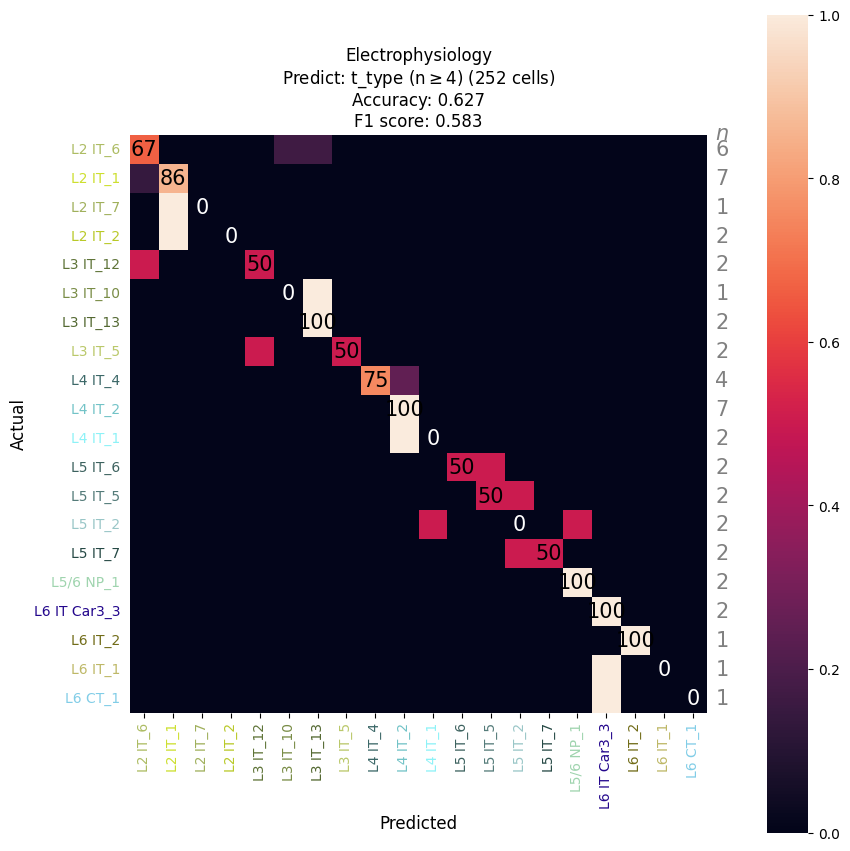

Subclass - withDepth
Fitting 3 folds for each of 81 candidates, totalling 243 fits
Best Parameters: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 150}
CV (n=3 folds) | Accuracy: 0.858 ± 0.027 | F1 (weighted): 0.852 ± 0.029


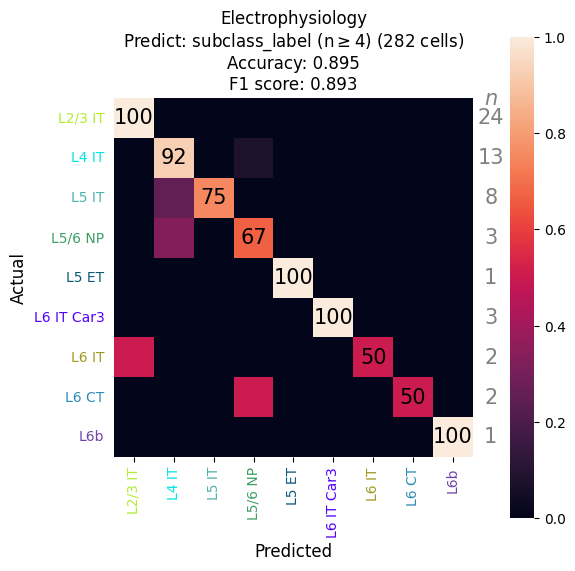

Subclass - withDepth
Fitting 3 folds for each of 81 candidates, totalling 243 fits
Best Parameters: {'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 150}
CV (n=3 folds) | Accuracy: 0.876 ± 0.025 | F1 (weighted): 0.869 ± 0.025


/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


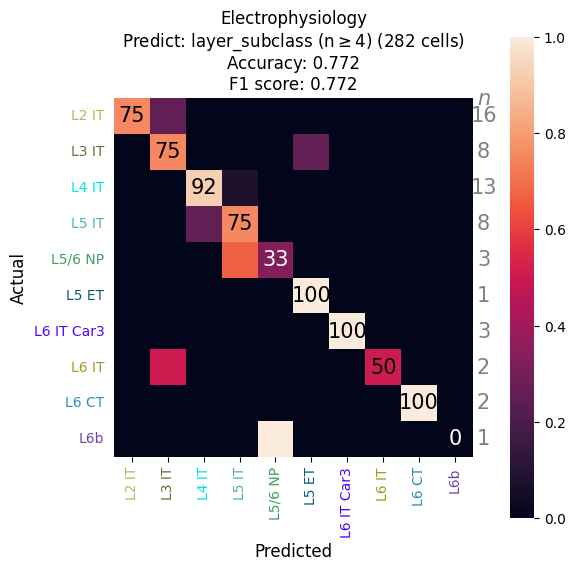

Subclass - withDepth
Fitting 3 folds for each of 81 candidates, totalling 243 fits
Best Parameters: {'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 150}
CV (n=3 folds) | Accuracy: 0.871 ± 0.027 | F1 (weighted): 0.871 ± 0.028


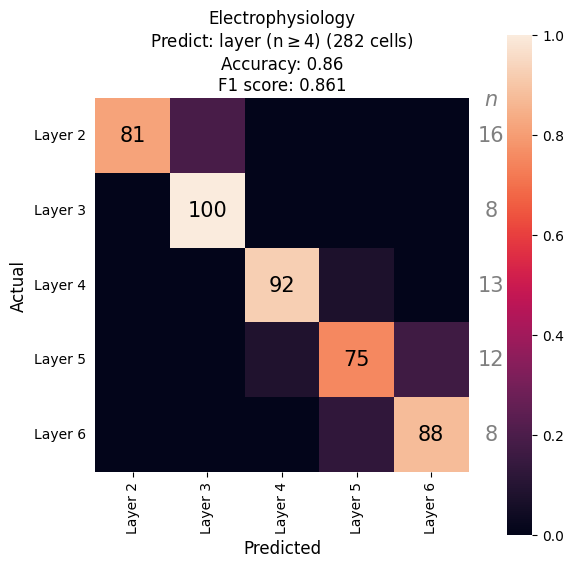

Subclass - withoutDepth
Fitting 3 folds for each of 81 candidates, totalling 243 fits
Best Parameters: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}
CV (n=3 folds) | Accuracy: 0.522 ± 0.042 | F1 (weighted): 0.478 ± 0.036


/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


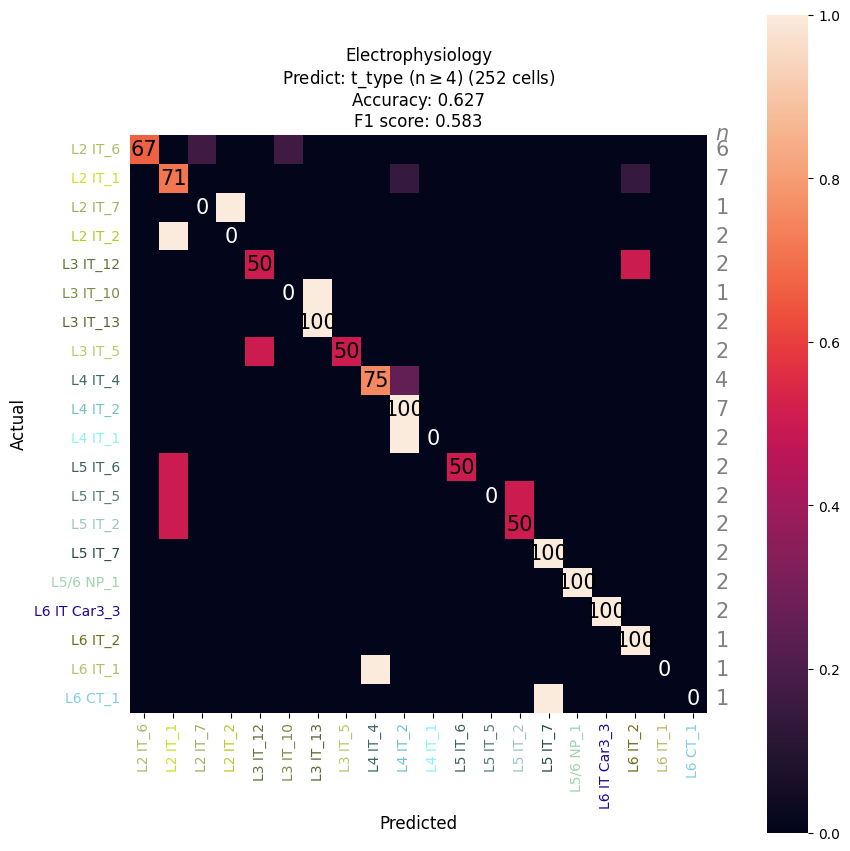

Subclass - withoutDepth
Fitting 3 folds for each of 81 candidates, totalling 243 fits
Best Parameters: {'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 150}
CV (n=3 folds) | Accuracy: 0.796 ± 0.023 | F1 (weighted): 0.777 ± 0.020


/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


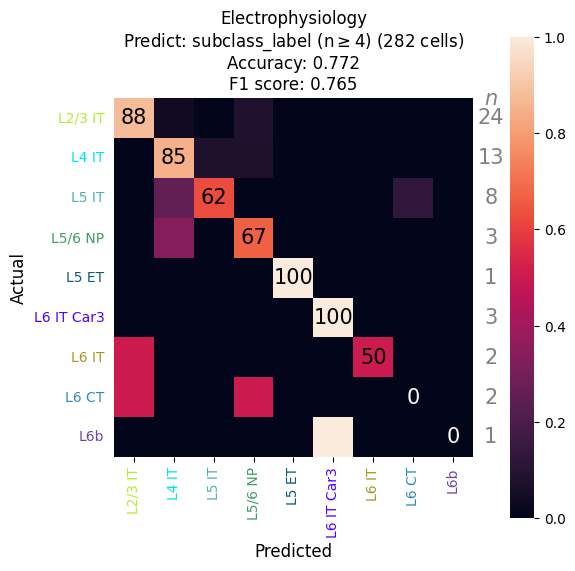

Subclass - withoutDepth
Fitting 3 folds for each of 81 candidates, totalling 243 fits
Best Parameters: {'max_depth': 15, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}
CV (n=3 folds) | Accuracy: 0.804 ± 0.035 | F1 (weighted): 0.790 ± 0.032


/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


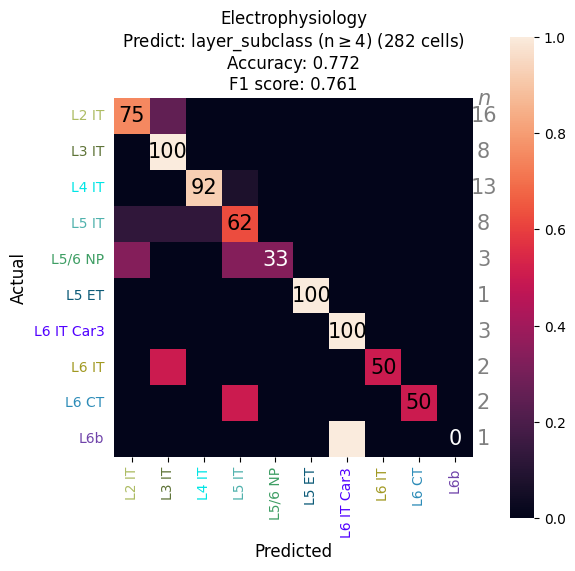

Subclass - withoutDepth
Fitting 3 folds for each of 81 candidates, totalling 243 fits
Best Parameters: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 150}
CV (n=3 folds) | Accuracy: 0.760 ± 0.033 | F1 (weighted): 0.757 ± 0.033


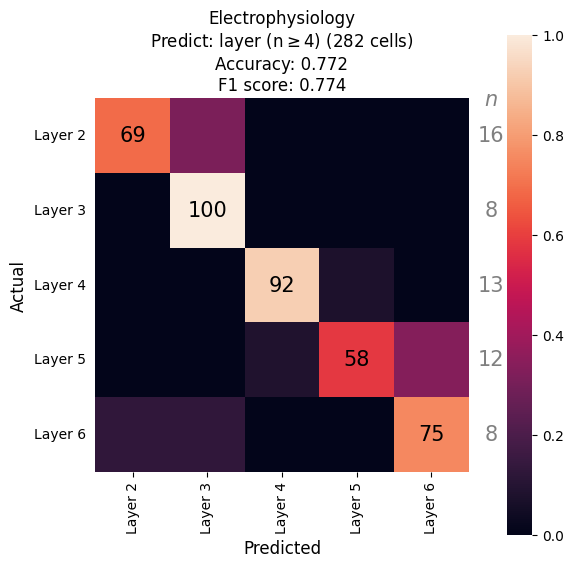

In [7]:
for stratify_type in stratify_types:
    for depth_type in depth_types:
        fig_path = os.path.join(out_dir, 'human_excitatory_ephys_classifier_rf_min_{}_cells_{}_stratify{}{}.pdf'.format(min_num_cells, depth_type, stratify_type, me_tag))
        with PdfPages(fig_path) as pdf:
            with warnings.catch_warnings():
                warnings.simplefilter(action='ignore', category=FutureWarning)

            for label_column in label_columns:

                print(f'{stratify_type} - {depth_type}')

                data = features_imputed
                feature_columns = cols = [c for c in data.columns if not c.endswith('label_Hierarchical')]
                if depth_type == 'withoutDepth':
                    feature_columns.remove('depth_from_pia_norm')

                #filter out data with a nan label_column value
                this_metadata = metadata.dropna(subset=label_column)

                id_column = 'specimen_id'
                data = data.merge(this_metadata, how='inner', left_index=True, right_index=True)
                labels = sorted(data[label_column].unique())

                #filter out data in [ttype] with less than n cells
                label_counts = data[label_column].value_counts()
                labels = sorted(label_counts[label_counts >= min_num_cells].index)
                labels = [l for l in label_order[label_column] if l in labels]
                data = data[data[label_column].isin(labels)]

                num_cells_total = len(data)

                #80/20 : train/test
                y = data[label_column]
                X = data[feature_columns]

                if stratify_type == 'Subclass':
                    X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(X, y, data.index, stratify=y, train_size=0.8, random_state=42)  #80/20 : train/test
                
                elif stratify_type == 'SubclassParadigm':
                    # stratify on both subclass and paradigm    
                    stratify_col = data[label_column].astype(str) + "_" + data["paradigm"].astype(str)

                    # Check whether stratification is possible
                    stratify_counts = stratify_col.value_counts()

                    if stratify_counts.min() < 2:
                        bad_groups = stratify_counts[stratify_counts < 2]

                        print(
                            f"Skipping {label_column} plot "
                            f"({stratify_type} - {depth_type}): "
                            f"stratification group(s) with fewer than 2 cells:"
                        )
                        print(bad_groups)

                        continue


                    X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(X, y, data.index, stratify=stratify_col, train_size=0.8, random_state=42)  #80/20 : train/test
                else:
                    raise ValueError(f"Unknown stratify_type: {stratify_type}")

                #normalize data
                scaler = StandardScaler() 
                X_train = scaler.fit_transform(X_train) 
                X_test = scaler.transform(X_test)

                #stratified kfold cross validation 
                cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

                #make model 
                rf_classifier = RandomForestClassifier(random_state=42, class_weight='balanced')

                # Hyperparameters to search
                param_grid = {
                    'n_estimators': [50, 100, 150],  
                    'max_depth': [5, 10, 15],
                    'min_samples_split': [2, 5, 10],
                    'min_samples_leaf': [1, 2, 4]
                }

                # Perform grid search
                scoring = {
                    'accuracy': 'accuracy',
                    'f1_weighted': 'f1_weighted'
                }

                grid_search = GridSearchCV(
                    rf_classifier,
                    param_grid,
                    cv=cv,
                    scoring=scoring,
                    refit='f1_weighted',   # important
                    verbose=1,
                    n_jobs=-1,
                    return_train_score=False
                )
                grid_search.fit(X_train, y_train)

                # Get the best model
                best_model = grid_search.best_estimator_
                print("Best Parameters:", grid_search.best_params_)

                cv_results = grid_search.cv_results_
                best_idx = grid_search.best_index_

                cv_acc_mean = cv_results['mean_test_accuracy'][best_idx]
                cv_acc_std  = cv_results['std_test_accuracy'][best_idx]

                cv_f1_mean  = cv_results['mean_test_f1_weighted'][best_idx]
                cv_f1_std   = cv_results['std_test_f1_weighted'][best_idx]

                print(
                    f"CV (n={cv.get_n_splits()} folds) | "
                    f"Accuracy: {cv_acc_mean:.3f} ± {cv_acc_std:.3f} | "
                    f"F1 (weighted): {cv_f1_mean:.3f} ± {cv_f1_std:.3f}"
                )

                #test
                y_pred = best_model.predict(X_test)

                #evaluate
                report = classification_report(y_test, y_pred, target_names=labels)
                accuracy = accuracy_score(y_test, y_pred)
                f1_test = f1_score(y_test, y_pred, average='weighted')
                cm = confusion_matrix(y_test, y_pred, labels=labels)
                true_label_counts = np.sum(cm, axis=1)
                normalized_cm = cm / true_label_counts[:, np.newaxis]
                row_acc = np.diag(normalized_cm)

                #PLOT
                fig, ax = plt.subplots(ncols=1, nrows=1, figsize=fig_sizes[label_column])

                formatted_labels = labels #[l[3:].replace('_', ' ') if l.startswith('Exc ') else l.replace('_', ' ') for l in labels]
                sns.heatmap(normalized_cm, annot=False, fmt=".2f", cmap="rocket", vmin=0, vmax=1, xticklabels=formatted_labels, yticklabels=formatted_labels, square=True, cbar=True, cbar_kws={"pad": 0.08})
                # Annotate diagonal with % correct per row
                for i in range(len(formatted_labels)):
                    val = row_acc[i]
                    ax.text(
                        i + 0.5,
                        i + 0.5,
                        f"{val*100:.0f}",
                        ha="center",
                        va="center",
                        fontsize=15,
                        color="white" if val < 0.5 else "black"
                    )

                plt.xlabel('Predicted', fontsize=12)
                plt.ylabel('Actual', fontsize=12)
                plt.title('Electrophysiology\nPredict: ' + label_column + r" (n$\geq${}) ({} cells)".format(min_num_cells, num_cells_total) + '\nAccuracy: ' + str(round(accuracy,3)) + '\nF1 score: ' + str(round(f1_test,3)), fontsize=12)
                plt.xticks(fontsize=10, rotation=90)  
                plt.yticks(fontsize=10, rotation=-0) 

                # Annotating counts on the right side
                for i in range(len(formatted_labels)):
                    ax.text(len(formatted_labels)+num_cell_xbuffer[label_column], i + 0.5 , int(true_label_counts[i]), ha="center", va="center", fontsize=15, color='grey')
                ax.text(len(formatted_labels)+num_cell_xbuffer[label_column], n_height[label_column] , 'n', ha="center", va="center", fontsize=15, color='grey', fontstyle='italic')

                # Removing the axis on the count side
                ax.tick_params(axis='y', which='both', left=False, right=False)

                if 'cluster' in label_column:
                    # Plot lines to separate subclasses
                    for i, l in enumerate(labels):
                        subclass = metadata[metadata[label_column] == l][label_column.replace('cluster', 'subclass')].unique()[0]
                        if i > 0:
                            if last_subclass != subclass:
                                ax.hlines(i, *ax.get_xlim(), color='white', linewidth=1)
                                ax.vlines(i, *ax.get_ylim(), color='white', linewidth=1)
                        last_subclass = subclass

                # Setting different colors for x and y tick labels
                for label in ax.get_xticklabels():
                    text = label.get_text()
                    # text = '_'.join(text.rsplit(' ', 1))
                    try:
                        label.set_color(color_dict[text])
                    except KeyError:
                        continue
                for label in ax.get_yticklabels():
                    text = label.get_text()
                    # text = '_'.join(text.rsplit(' ', 1))
                    try:
                        label.set_color(color_dict[text])
                    except KeyError:
                        continue

                plt.tight_layout()
                pdf.savefig(fig, bbox_inches='tight')
                plt.show()


### Predict labels within each layer

RF params

In [ ]:
group_column = 'layer'
label_columns = ['t_type', 'subclass_label']
stratify_types = ['Subclass', 'SubclassParadigm']
depth_types = ['withDepth', 'withoutDepth']
min_num_cells = 3

num_cell_xbuffer[group_column] = 0.3
fig_sizes[group_column] = (6,6) 
n_height[group_column] = 0.015 

groups = sorted(metadata[group_column].unique().tolist())
groups

['Layer 2', 'Layer 3', 'Layer 4', 'Layer 5', 'Layer 6']

RF classifiers

Fitting 3 folds for each of 81 candidates, totalling 243 fits
Best Parameters: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 150}


/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


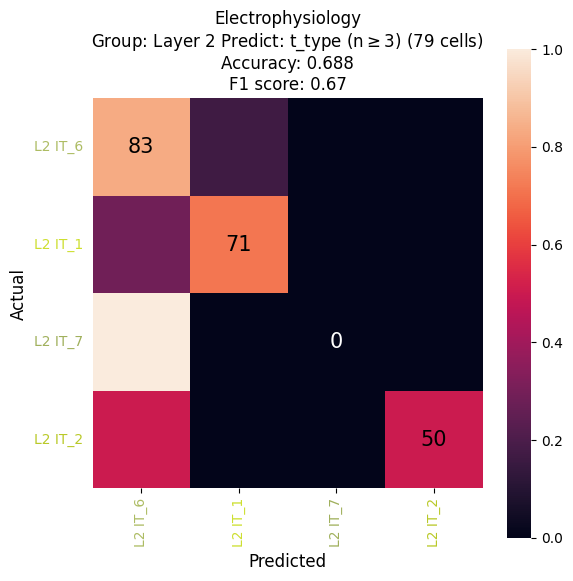

Removing subclass_label gropus with fewer than 3 cells left less than 2 types to predict. Skipping this group Layer 2.
Fitting 3 folds for each of 81 candidates, totalling 243 fits
Best Parameters: {'max_depth': 5, 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 150}


/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


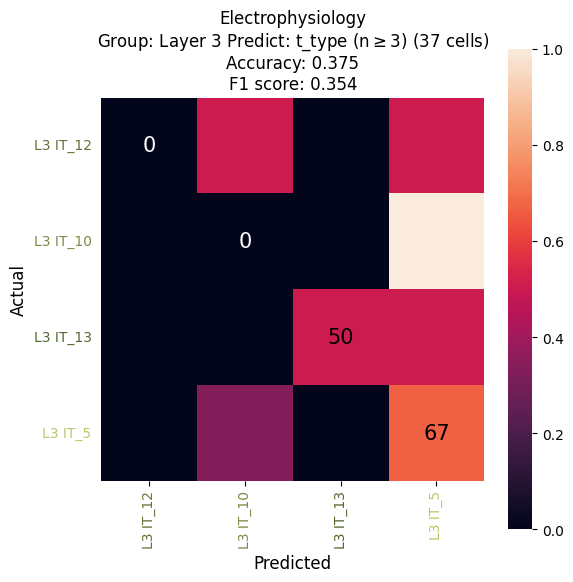

Removing subclass_label gropus with fewer than 3 cells left less than 2 types to predict. Skipping this group Layer 3.
Fitting 3 folds for each of 81 candidates, totalling 243 fits
Best Parameters: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 50}


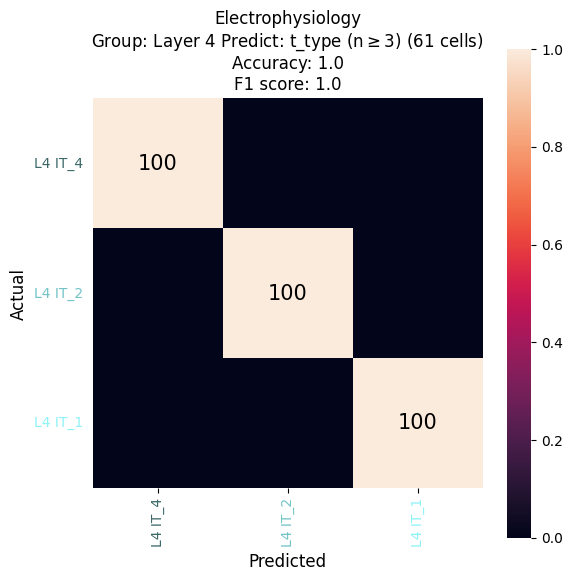

Removing subclass_label gropus with fewer than 3 cells left less than 2 types to predict. Skipping this group Layer 4.
Fitting 3 folds for each of 81 candidates, totalling 243 fits


/opt/conda/lib/python3.10/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(


Best Parameters: {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 150}


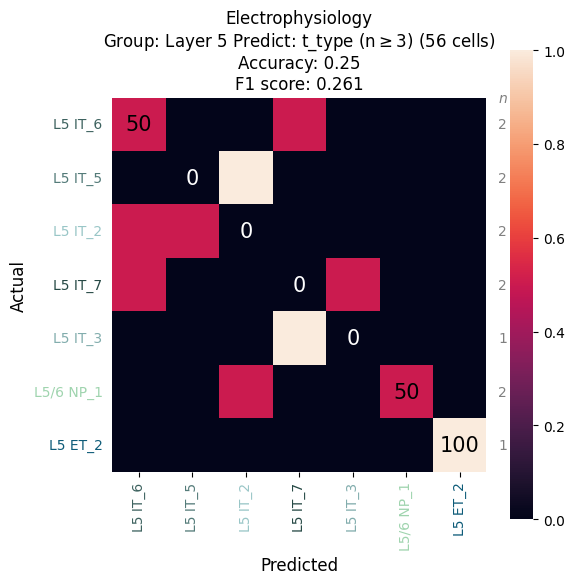

Fitting 3 folds for each of 81 candidates, totalling 243 fits
Best Parameters: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 150}


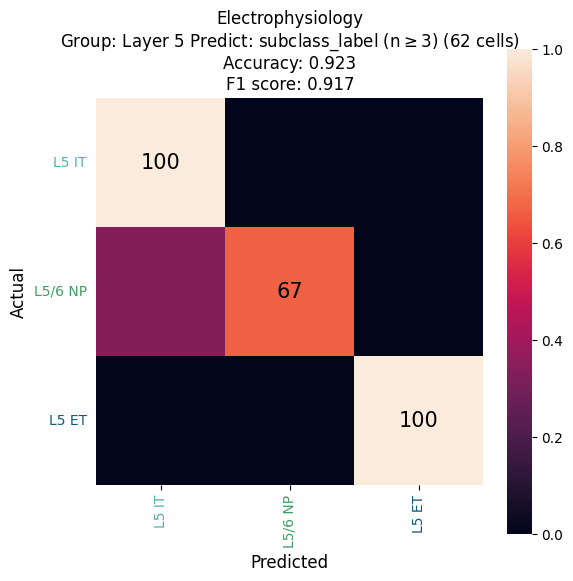

Fitting 3 folds for each of 81 candidates, totalling 243 fits


/opt/conda/lib/python3.10/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(


Best Parameters: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 150}


/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


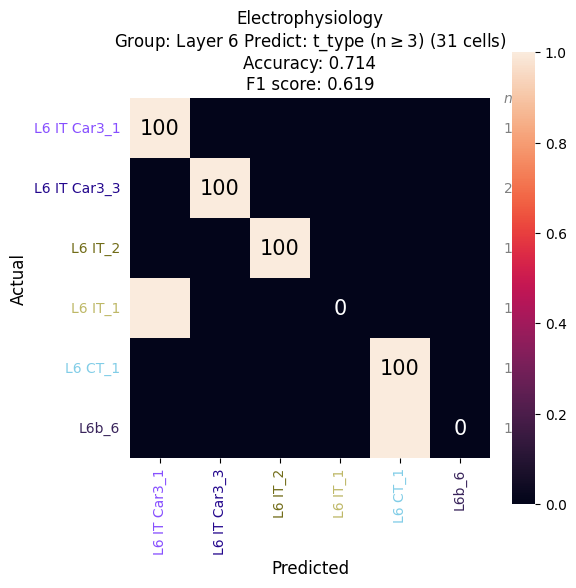

Fitting 3 folds for each of 81 candidates, totalling 243 fits
Best Parameters: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}


/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


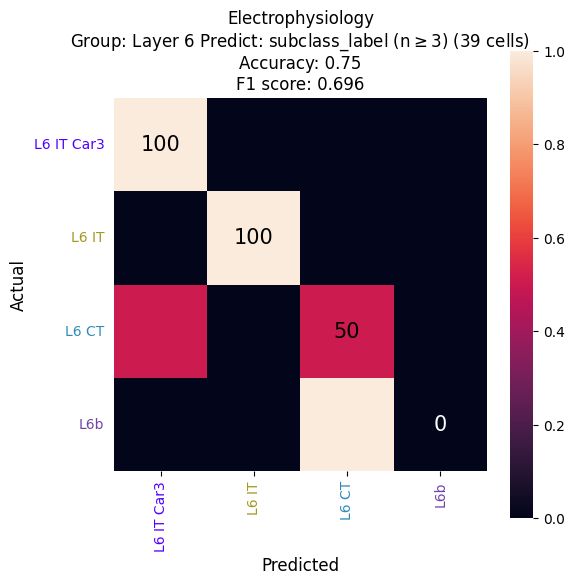

Fitting 3 folds for each of 81 candidates, totalling 243 fits
Best Parameters: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}


/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


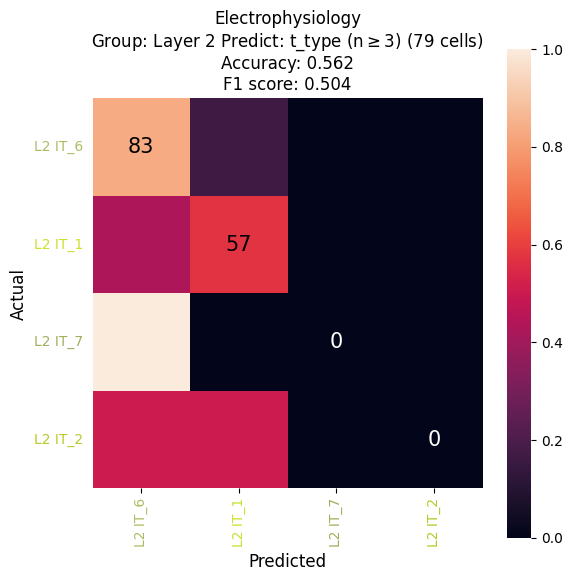

Removing subclass_label gropus with fewer than 3 cells left less than 2 types to predict. Skipping this group Layer 2.
Fitting 3 folds for each of 81 candidates, totalling 243 fits
Best Parameters: {'max_depth': 5, 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 50}


/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


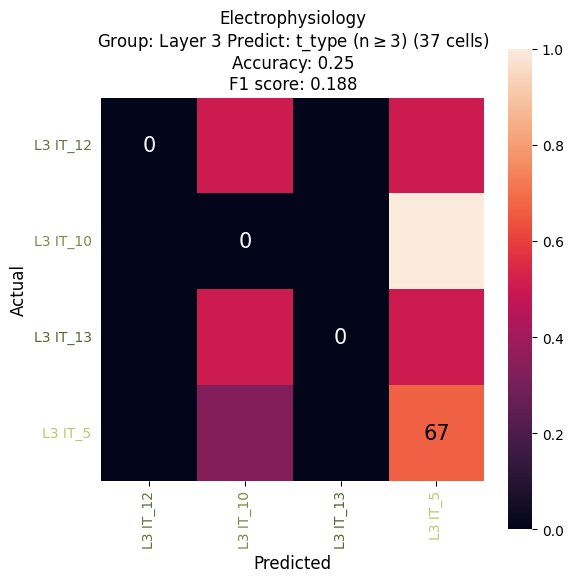

Removing subclass_label gropus with fewer than 3 cells left less than 2 types to predict. Skipping this group Layer 3.
Fitting 3 folds for each of 81 candidates, totalling 243 fits
Best Parameters: {'max_depth': 5, 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 50}


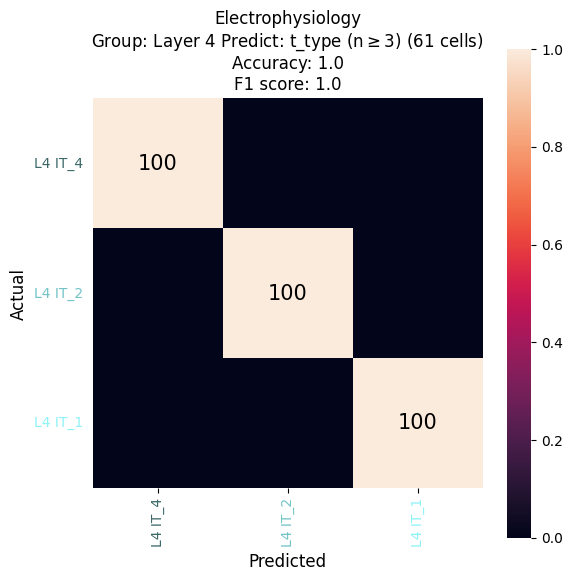

Removing subclass_label gropus with fewer than 3 cells left less than 2 types to predict. Skipping this group Layer 4.
Fitting 3 folds for each of 81 candidates, totalling 243 fits


/opt/conda/lib/python3.10/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(


Best Parameters: {'max_depth': 5, 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 150}


/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


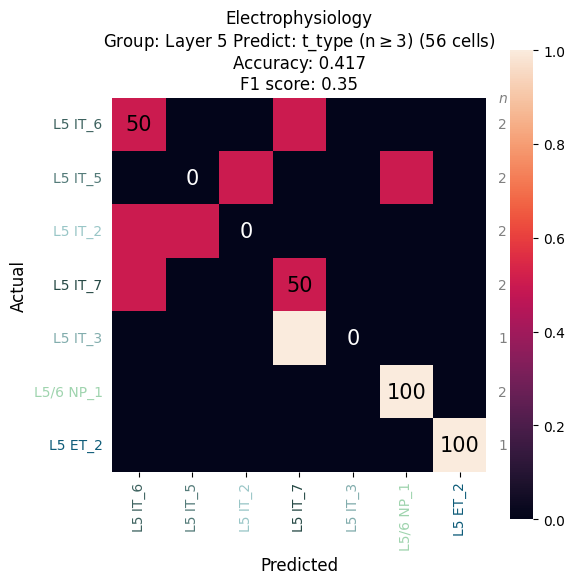

Fitting 3 folds for each of 81 candidates, totalling 243 fits
Best Parameters: {'max_depth': 5, 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 150}


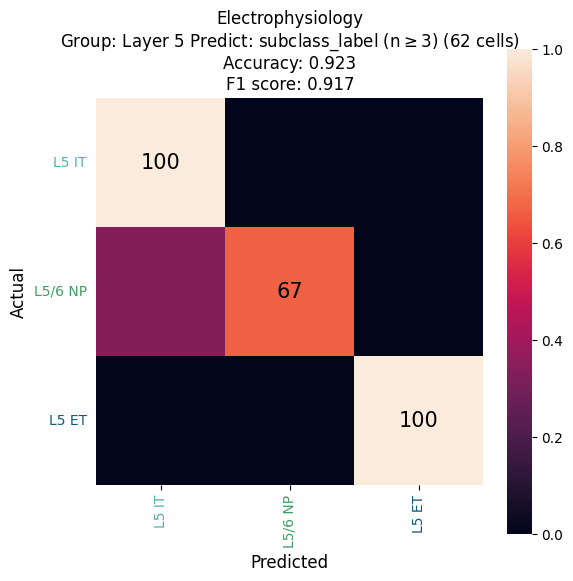

Fitting 3 folds for each of 81 candidates, totalling 243 fits


/opt/conda/lib/python3.10/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(


Best Parameters: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 50}


/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


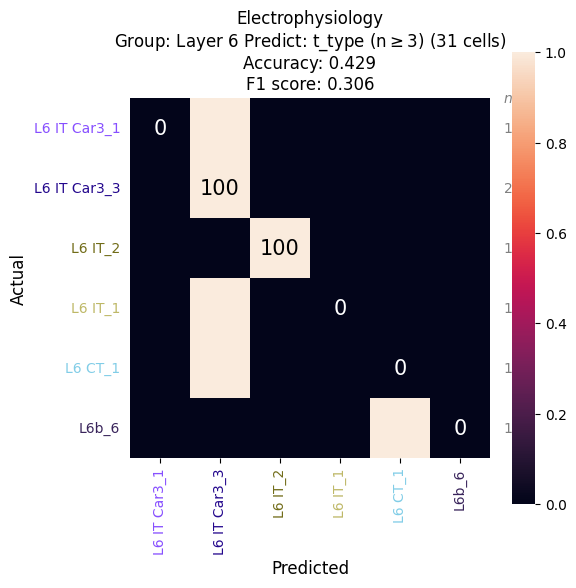

Fitting 3 folds for each of 81 candidates, totalling 243 fits
Best Parameters: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 150}


/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


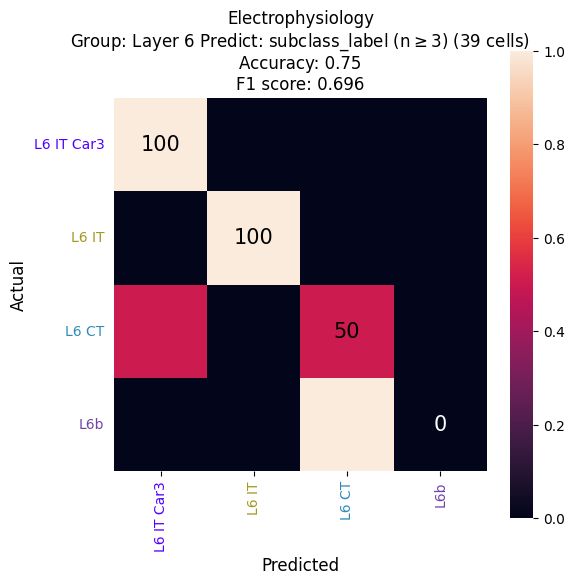

Skipping t_type plot (SubclassParadigm - withDepth): stratification group(s) with fewer than 2 cells:
L2 IT_2_culture    1
L2 IT_1_culture    1
L2 IT_7_culture    1
dtype: int64
Removing subclass_label gropus with fewer than 3 cells left less than 2 types to predict. Skipping this group Layer 2.
Skipping t_type plot (SubclassParadigm - withDepth): stratification group(s) with fewer than 2 cells:
L3 IT_12_culture    1
dtype: int64
Removing subclass_label gropus with fewer than 3 cells left less than 2 types to predict. Skipping this group Layer 3.
Fitting 3 folds for each of 81 candidates, totalling 243 fits
Best Parameters: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 50}


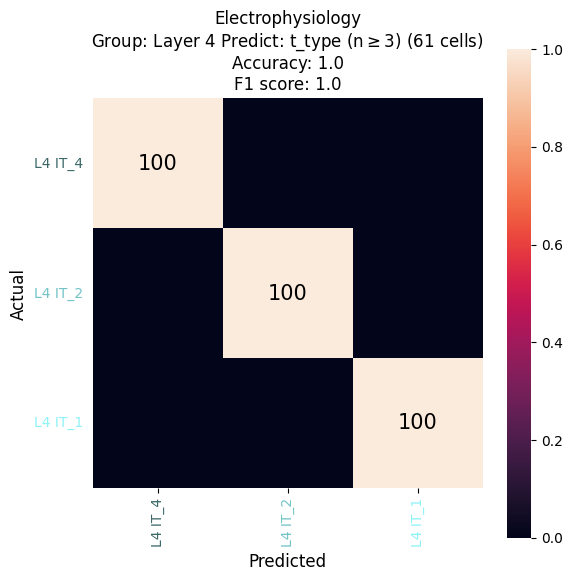

Removing subclass_label gropus with fewer than 3 cells left less than 2 types to predict. Skipping this group Layer 4.
Skipping t_type plot (SubclassParadigm - withDepth): stratification group(s) with fewer than 2 cells:
L5 ET_2_acute      1
L5 IT_3_acute      1
L5 IT_6_culture    1
dtype: int64
Fitting 3 folds for each of 81 candidates, totalling 243 fits
Best Parameters: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 150}


/tmp/ipykernel_1202440/3881115936.py:107: RuntimeWarning: invalid value encountered in divide
  normalized_cm = cm / true_label_counts[:, np.newaxis]


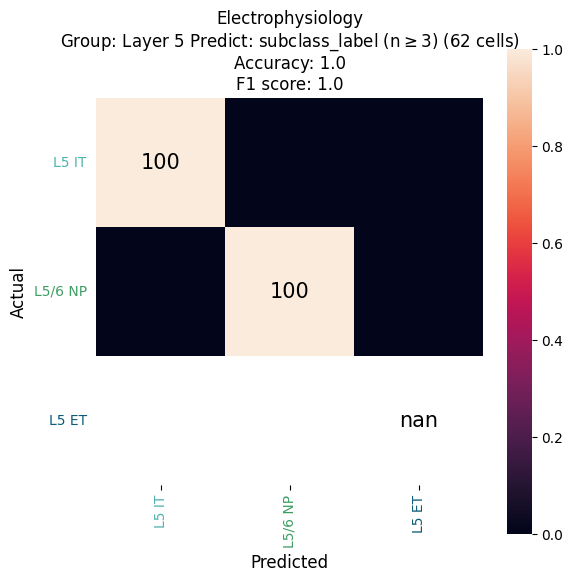

Skipping t_type plot (SubclassParadigm - withDepth): stratification group(s) with fewer than 2 cells:
L6 IT_2_acute      1
L6b_6_acute        1
L6 CT_1_acute      1
L6 IT_1_culture    1
dtype: int64
Fitting 3 folds for each of 81 candidates, totalling 243 fits
Best Parameters: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 150}


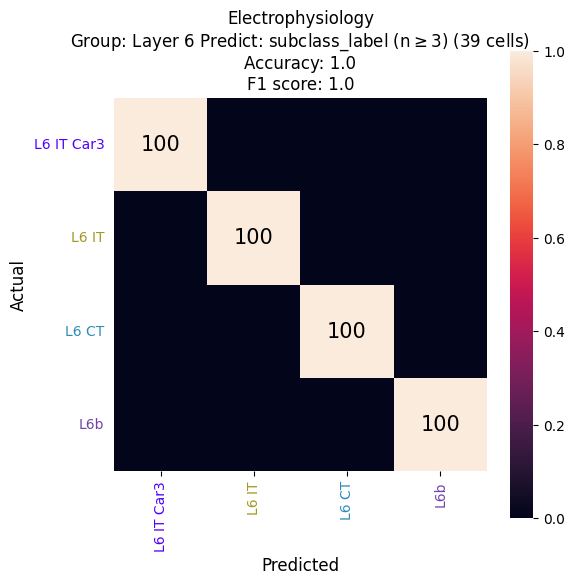

Skipping t_type plot (SubclassParadigm - withoutDepth): stratification group(s) with fewer than 2 cells:
L2 IT_2_culture    1
L2 IT_1_culture    1
L2 IT_7_culture    1
dtype: int64
Removing subclass_label gropus with fewer than 3 cells left less than 2 types to predict. Skipping this group Layer 2.
Skipping t_type plot (SubclassParadigm - withoutDepth): stratification group(s) with fewer than 2 cells:
L3 IT_12_culture    1
dtype: int64
Removing subclass_label gropus with fewer than 3 cells left less than 2 types to predict. Skipping this group Layer 3.
Fitting 3 folds for each of 81 candidates, totalling 243 fits
Best Parameters: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 50}


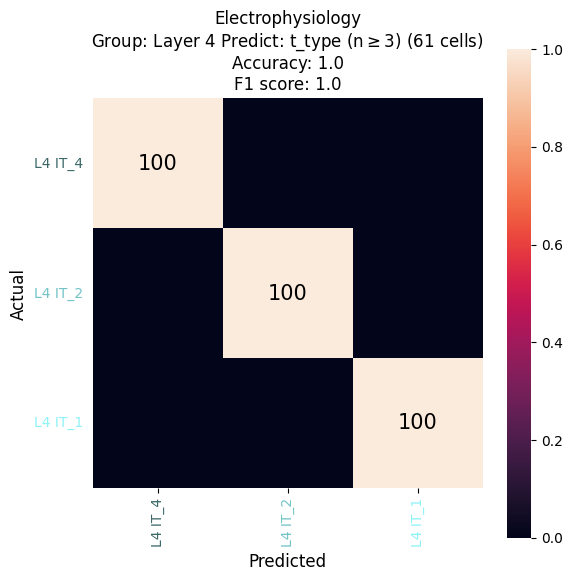

Removing subclass_label gropus with fewer than 3 cells left less than 2 types to predict. Skipping this group Layer 4.
Skipping t_type plot (SubclassParadigm - withoutDepth): stratification group(s) with fewer than 2 cells:
L5 ET_2_acute      1
L5 IT_3_acute      1
L5 IT_6_culture    1
dtype: int64
Fitting 3 folds for each of 81 candidates, totalling 243 fits
Best Parameters: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 150}


/tmp/ipykernel_1202440/3881115936.py:107: RuntimeWarning: invalid value encountered in divide
  normalized_cm = cm / true_label_counts[:, np.newaxis]


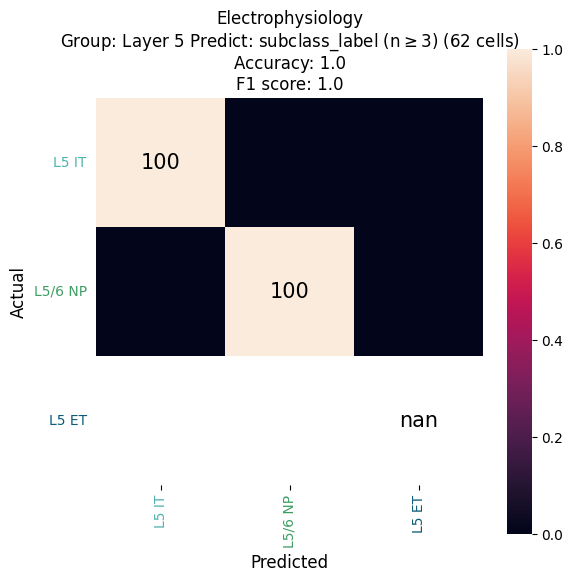

Skipping t_type plot (SubclassParadigm - withoutDepth): stratification group(s) with fewer than 2 cells:
L6 IT_2_acute      1
L6b_6_acute        1
L6 CT_1_acute      1
L6 IT_1_culture    1
dtype: int64
Fitting 3 folds for each of 81 candidates, totalling 243 fits
Best Parameters: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 150}


/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


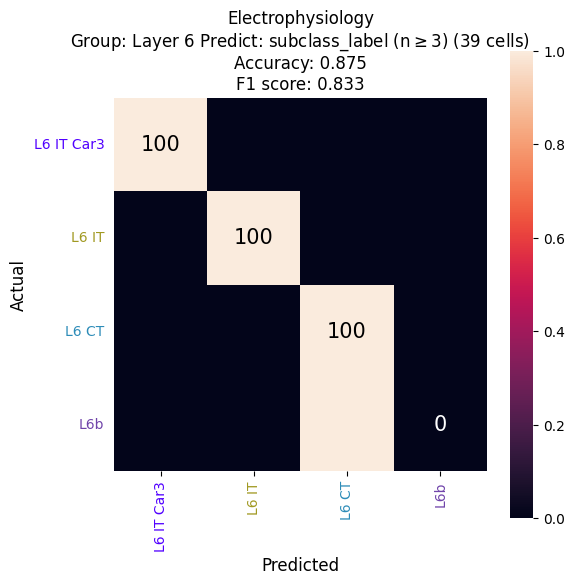

In [ ]:
for stratify_type in stratify_types:
    for depth_type in depth_types:
        fig_path = os.path.join(out_dir, 'human_excitatory_ephys_classifier_rf_min_{}_cells_group_{}_{}_stratify{}{}.pdf'.format(min_num_cells, group_column, depth_type, stratify_type, me_tag))        
        with PdfPages(fig_path) as pdf:
            with warnings.catch_warnings():
                warnings.simplefilter(action='ignore', category=FutureWarning)

            for group in groups:

                for label_column in label_columns:
            
                    data = features_imputed
                    feature_columns = cols = [c for c in data.columns if not c.endswith('label_Hierarchical')]
                    if depth_type == 'withoutDepth':
                        feature_columns.remove('depth_from_pia_norm')

                    #filter out data with a nan label_column value
                    this_metadata = metadata[metadata[group_column] == group].dropna(subset=label_column)

                    id_column = 'specimen_id'
                    data = data.merge(this_metadata, how='inner', left_index=True, right_index=True)
                    labels = sorted(data[label_column].unique())

                    #filter out data in [ttype] with less than n cells
                    label_counts = data[label_column].value_counts()
                    labels = sorted(label_counts[label_counts >= min_num_cells].index)
                    labels = [l for l in label_order[label_column] if l in labels]
                    data = data[data[label_column].isin(labels)]

                    #make sure there are at least two label_column values left in data
                    if len(this_metadata[this_metadata.index.isin(data.index.tolist())][label_column].unique()) < 2: 
                        print(f"Removing {label_column} gropus with fewer than {min_num_cells} cells left less than 2 types to predict. Skipping this group {group}.")
                        continue


                    num_cells_total = len(data)

                    #80/20 : train/test
                    y = data[label_column]
                    X = data[feature_columns]

                    if stratify_type == 'Subclass':
                        X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(X, y, data.index, stratify=y, train_size=0.8, random_state=42)  #80/20 : train/test
                    
                    elif stratify_type == 'SubclassParadigm':
                        # stratify on both subclass and paradigm    
                        stratify_col = data[label_column].astype(str) + "_" + data["paradigm"].astype(str)

                        # Check whether stratification is possible
                        stratify_counts = stratify_col.value_counts()

                        if stratify_counts.min() < 2:
                            bad_groups = stratify_counts[stratify_counts < 2]

                            print(
                                f"Skipping {label_column} plot "
                                f"({stratify_type} - {depth_type}): "
                                f"stratification group(s) with fewer than 2 cells:"
                            )
                            print(bad_groups)

                            continue

                        X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(X, y, data.index, stratify=stratify_col, train_size=0.8, random_state=42)  #80/20 : train/test
                    else:
                        raise ValueError(f"Unknown stratify_type: {stratify_type}")


                    #normalize data
                    scaler = StandardScaler() 
                    X_train = scaler.fit_transform(X_train) 
                    X_test = scaler.transform(X_test)

                    #stratified kfold cross validation 
                    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

                    #make model 
                    rf_classifier = RandomForestClassifier(random_state=42, class_weight='balanced')

                    # Hyperparameters to search
                    param_grid = {
                        'n_estimators': [50, 100, 150],  
                        'max_depth': [5, 10, 15],
                        'min_samples_split': [2, 5, 10],
                        'min_samples_leaf': [1, 2, 4]
                    }

                    # Perform grid search
                    grid_search = GridSearchCV(rf_classifier, param_grid, cv=cv, verbose=1, n_jobs=-1)
                    grid_search.fit(X_train, y_train)

                    # Get the best model
                    best_model = grid_search.best_estimator_
                    print("Best Parameters:", grid_search.best_params_)

                    #test
                    y_pred = best_model.predict(X_test)

                    #evaluate
                    # target_names = [l for l in labels if l in sorted(set(y_test))]
                    target_names = sorted(set(y_test.values) | set(y_pred))
                    report = classification_report(y_test, y_pred, target_names=target_names)
                    accuracy = accuracy_score(y_test, y_pred)
                    f1_test = f1_score(y_test, y_pred, average='weighted')
                    cm = confusion_matrix(y_test, y_pred, labels=labels)
                    true_label_counts = np.sum(cm, axis=1)
                    normalized_cm = cm / true_label_counts[:, np.newaxis]
                    row_acc = np.diag(normalized_cm)

                    #PLOT
                    fig, ax = plt.subplots(ncols=1, nrows=1, figsize=fig_sizes[group_column])

                    formatted_labels = labels
                    sns.heatmap(normalized_cm, annot=False, fmt=".2f", cmap="rocket", vmin=0, vmax=1, xticklabels=formatted_labels, yticklabels=formatted_labels, square=True, cbar=True)
                    # Annotate diagonal with % correct per row
                    for i in range(len(formatted_labels)):
                        val = row_acc[i]
                        ax.text(
                            i + 0.5,
                            i + 0.5,
                            f"{val*100:.0f}",
                            ha="center",
                            va="center",
                            fontsize=15,
                            color="white" if val < 0.5 else "black"
                        )

                    plt.xlabel('Predicted', fontsize=12)
                    plt.ylabel('Actual', fontsize=12)
                    plt.title(f'Electrophysiology\nGroup: {group} Predict: {label_column}' + r" (n$\geq${}) ({} cells)".format(min_num_cells, num_cells_total) + '\nAccuracy: ' + str(round(accuracy,3)) + '\nF1 score: ' + str(round(f1_test,3)), fontsize=12)
                    plt.xticks(fontsize=10, rotation=90)  
                    plt.yticks(fontsize=10, rotation=-0) 

                    # Annotating counts on the right side
                    for i in range(len(formatted_labels)):
                        ax.text(len(formatted_labels)+num_cell_xbuffer[group_column], i + 0.5 , int(true_label_counts[i]), ha="center", va="center", fontsize=10, color='grey')
                    ax.text(len(formatted_labels)+num_cell_xbuffer[group_column], n_height[group_column] , 'n', ha="center", va="center", fontsize=10, color='grey', fontstyle='italic')

                    # Removing the axis on the count side
                    ax.tick_params(axis='y', which='both', left=False, right=False)

                    if 'cluster' in label_column:
                        # Plot lines to separate subclasses
                        for i, l in enumerate(labels):
                            subclass = metadata[metadata[label_column] == l][label_column.replace('cluster', 'subclass')].unique()[0]
                            if i > 0:
                                if last_subclass != subclass:
                                    ax.hlines(i, *ax.get_xlim(), color='white', linewidth=1)
                                    ax.vlines(i, *ax.get_ylim(), color='white', linewidth=1)
                            last_subclass = subclass

                    # Setting different colors for x and y tick labels
                    for label in ax.get_xticklabels():
                        text = label.get_text()
                        # text = '_'.join(text.rsplit(' ', -1))
                        try:
                            label.set_color(color_dict[text])
                        except KeyError:
                            continue
                    for label in ax.get_yticklabels():
                        text = label.get_text()
                        # text = '_'.join(text.rsplit(' ', -1))
                        try:
                            label.set_color(color_dict[text])
                        except KeyError:
                            continue

                    plt.tight_layout()
                    pdf.savefig(fig, bbox_inches='tight')
                    plt.show()

### Acute/Culture classifiers

1. Acute-only classifier

In [10]:
label_columns = ['subclass_label']
depth_types = ['withDepth', 'withoutDepth']
min_num_cells = 3

Fitting 3 folds for each of 81 candidates, totalling 243 fits
Best Parameters: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 150}
CV (n=3 folds) | Accuracy: 0.896 ± 0.039 | F1 (weighted): 0.887 ± 0.040


/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


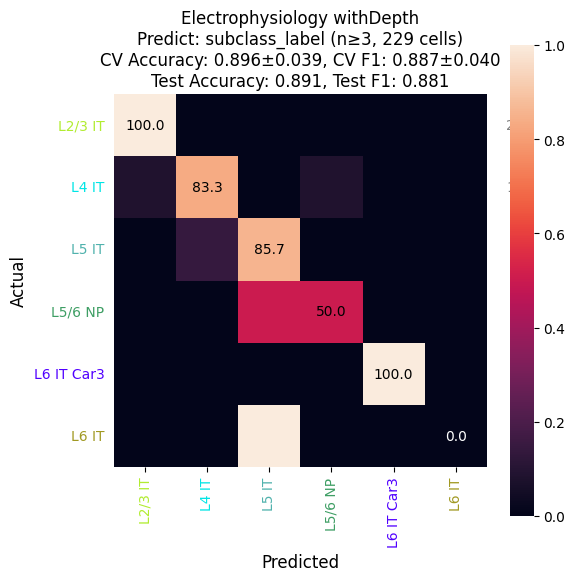

Fitting 3 folds for each of 81 candidates, totalling 243 fits
Best Parameters: {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 150}
CV (n=3 folds) | Accuracy: 0.836 ± 0.035 | F1 (weighted): 0.818 ± 0.034


/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


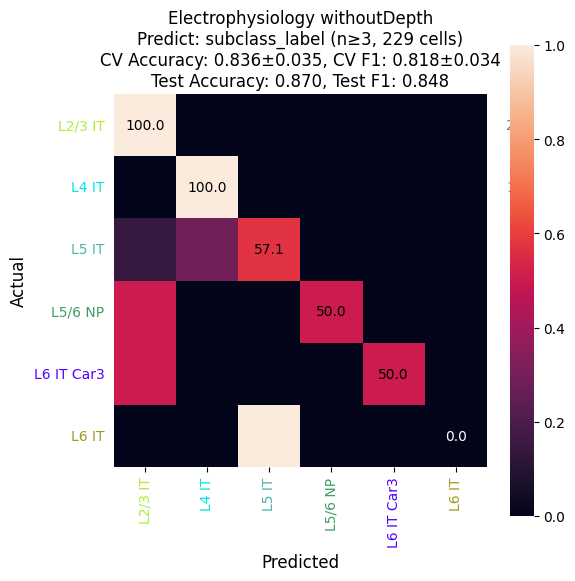

In [11]:
for depth_type in depth_types:
    fig_path = os.path.join(out_dir, 'human_excitatory_ephys_classifier_rf_min_{}_cells_{}_acuteOnly{}.pdf'.format(min_num_cells, depth_type, me_tag))
    with PdfPages(fig_path) as pdf:
        with warnings.catch_warnings():
            warnings.simplefilter(action='ignore', category=FutureWarning)

        for label_column in label_columns:

            data = features_imputed
            feature_columns = cols = [c for c in data.columns if not c.endswith('_label_Hierarchical')]
            if depth_type == 'withoutDepth':
                feature_columns.remove('depth_from_pia_norm')

            #filter out data with a nan label_column value
            this_metadata = metadata.dropna(subset=label_column)

            #only keep acute data
            this_metadata = this_metadata[this_metadata.paradigm == 'acute']

            id_column = 'specimen_id'
            data = data.merge(this_metadata, how='inner', left_index=True, right_index=True)
            labels = sorted(data[label_column].unique())

            #filter out data in [ttype] with less than n cells
            label_counts = data[label_column].value_counts()
            labels = sorted(label_counts[label_counts >= min_num_cells].index)
            labels = [l for l in label_order[label_column] if l in labels]
            data = data[data[label_column].isin(labels)]

            num_cells_total = len(data)

            #80/20 : train/test
            y = data[label_column]
            X = data[feature_columns]
            X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(X, y, data.index, stratify=y, train_size=0.8, random_state=42)  #80/20 : train/test

            #normalize data
            scaler = StandardScaler() 
            X_train = scaler.fit_transform(X_train) 
            X_test = scaler.transform(X_test)

            #stratified kfold cross validation 
            cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

            #make model 
            rf_classifier = RandomForestClassifier(random_state=42, class_weight='balanced')

            # Hyperparameters to search
            param_grid = {
                'n_estimators': [50, 100, 150],  
                'max_depth': [5, 10, 15],
                'min_samples_split': [2, 5, 10],
                'min_samples_leaf': [1, 2, 4]
            }

            # Perform grid search
            scoring = {
                'accuracy': 'accuracy',
                'f1_weighted': 'f1_weighted'
            }

            grid_search = GridSearchCV(
                rf_classifier,
                param_grid,
                cv=cv,
                scoring=scoring,
                refit='f1_weighted',   # important
                verbose=1,
                n_jobs=-1,
                return_train_score=False
            )
            grid_search.fit(X_train, y_train)

            # Get the best model
            best_model = grid_search.best_estimator_
            print("Best Parameters:", grid_search.best_params_)

            cv_results = grid_search.cv_results_
            best_idx = grid_search.best_index_

            cv_acc_mean = cv_results['mean_test_accuracy'][best_idx]
            cv_acc_std  = cv_results['std_test_accuracy'][best_idx]

            cv_f1_mean  = cv_results['mean_test_f1_weighted'][best_idx]
            cv_f1_std   = cv_results['std_test_f1_weighted'][best_idx]

            print(
                f"CV (n={cv.get_n_splits()} folds) | "
                f"Accuracy: {cv_acc_mean:.3f} ± {cv_acc_std:.3f} | "
                f"F1 (weighted): {cv_f1_mean:.3f} ± {cv_f1_std:.3f}"
            )

            #test
            y_pred = best_model.predict(X_test)

            #evaluate
            report = classification_report(y_test, y_pred, target_names=labels)
            accuracy = accuracy_score(y_test, y_pred)
            f1_test = f1_score(y_test, y_pred, average='weighted')
            cm = confusion_matrix(y_test, y_pred, labels=labels)
            true_label_counts = np.sum(cm, axis=1)
            normalized_cm = cm / true_label_counts[:, np.newaxis]
            row_acc = np.diag(normalized_cm)

            #PLOT
            fig, ax = plt.subplots(ncols=1, nrows=1, figsize=fig_sizes[label_column])

            formatted_labels = labels #[l[3:].replace('_', ' ') if l.startswith('Exc ') else l.replace('_', ' ') for l in labels]
            sns.heatmap(normalized_cm, annot=False, fmt=".2f", cmap="rocket", vmin=0, vmax=1, xticklabels=formatted_labels, yticklabels=formatted_labels, square=True, cbar=True)
            # Annotate diagonal with % correct per row
            for i in range(len(formatted_labels)):
                val = row_acc[i]
                ax.text(
                    i + 0.5,
                    i + 0.5,
                    f"{val*100:.1f}",
                    ha="center",
                    va="center",
                    fontsize=10,
                    color="white" if val < 0.5 else "black"
                )

            plt.xlabel('Predicted', fontsize=12)
            plt.ylabel('Actual', fontsize=12)
            plt.title(
                f'Electrophysiology {depth_type}\n'
                f'Predict: {label_column} (n≥{min_num_cells}, {num_cells_total} cells)\n'
                f'CV Accuracy: {cv_acc_mean:.3f}±{cv_acc_std:.3f}, '
                f'CV F1: {cv_f1_mean:.3f}±{cv_f1_std:.3f}\n'
                f'Test Accuracy: {accuracy:.3f}, Test F1: {f1_test:.3f}',
                fontsize=12
            )

            plt.xticks(fontsize=10, rotation=90)  
            plt.yticks(fontsize=10, rotation=-0) 

            # Annotating counts on the right side
            for i in range(len(formatted_labels)):
                ax.text(len(formatted_labels)+num_cell_xbuffer[label_column], i + 0.5 , int(true_label_counts[i]), ha="center", va="center", fontsize=10, color='grey')
            ax.text(len(formatted_labels)+num_cell_xbuffer[label_column], n_height[label_column] , 'n', ha="center", va="center", fontsize=10, color='grey', fontstyle='italic')

            # Removing the axis on the count side
            ax.tick_params(axis='y', which='both', left=False, right=False)

            if 'cluster' in label_column:
                # Plot lines to separate subclasses
                for i, l in enumerate(labels):
                    subclass = metadata[metadata[label_column] == l][label_column.replace('cluster', 'subclass')].unique()[0]
                    if i > 0:
                        if last_subclass != subclass:
                            ax.hlines(i, *ax.get_xlim(), color='white', linewidth=1)
                            ax.vlines(i, *ax.get_ylim(), color='white', linewidth=1)
                    last_subclass = subclass

            # Setting different colors for x and y tick labels
            for label in ax.get_xticklabels():
                text = label.get_text()
                # text = '_'.join(text.rsplit(' ', 1))
                try:
                    label.set_color(color_dict[text])
                except KeyError:
                    continue
            for label in ax.get_yticklabels():
                text = label.get_text()
                # text = '_'.join(text.rsplit(' ', 1))
                try:
                    label.set_color(color_dict[text])
                except KeyError:
                    continue

            plt.tight_layout()
            pdf.savefig(fig, bbox_inches='tight')
            plt.show()


2. Train on acute, predict culture


withDepth | subclass_label
Acute cells: 229
Culture cells: 35
Acute paradigms: ['acute']
Culture paradigms: ['culture']
Labels: ['L2/3 IT', 'L4 IT', 'L5 IT', 'L5/6 NP', 'L6 IT Car3', 'L6 IT']
Train labels: ['L2/3 IT', 'L4 IT', 'L5 IT', 'L5/6 NP', 'L6 IT', 'L6 IT Car3']
Acute test labels: ['L2/3 IT', 'L4 IT', 'L5 IT', 'L5/6 NP', 'L6 IT', 'L6 IT Car3']
Culture labels: ['L2/3 IT', 'L4 IT', 'L5 IT', 'L5/6 NP', 'L6 IT', 'L6 IT Car3']
Fitting 3 folds for each of 81 candidates, totalling 243 fits
Best Parameters: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 150}
CV acute train | Accuracy: 0.896 ± 0.039 | F1 weighted: 0.887 ± 0.040
Held-out acute test | Accuracy: 0.891 | F1: 0.881
Culture apply/test | Accuracy: 0.714 | F1: 0.642


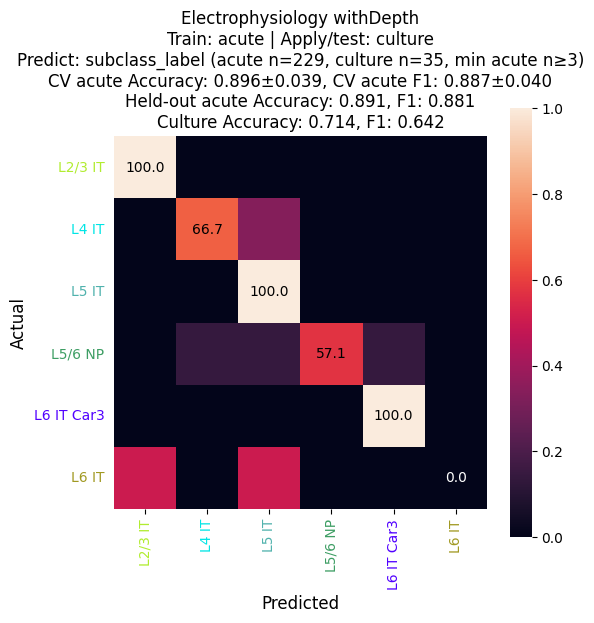


withoutDepth | subclass_label
Acute cells: 229
Culture cells: 35
Acute paradigms: ['acute']
Culture paradigms: ['culture']
Labels: ['L2/3 IT', 'L4 IT', 'L5 IT', 'L5/6 NP', 'L6 IT Car3', 'L6 IT']
Train labels: ['L2/3 IT', 'L4 IT', 'L5 IT', 'L5/6 NP', 'L6 IT', 'L6 IT Car3']
Acute test labels: ['L2/3 IT', 'L4 IT', 'L5 IT', 'L5/6 NP', 'L6 IT', 'L6 IT Car3']
Culture labels: ['L2/3 IT', 'L4 IT', 'L5 IT', 'L5/6 NP', 'L6 IT', 'L6 IT Car3']
Fitting 3 folds for each of 81 candidates, totalling 243 fits
Best Parameters: {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 150}
CV acute train | Accuracy: 0.836 ± 0.035 | F1 weighted: 0.818 ± 0.034
Held-out acute test | Accuracy: 0.870 | F1: 0.848
Culture apply/test | Accuracy: 0.600 | F1: 0.543


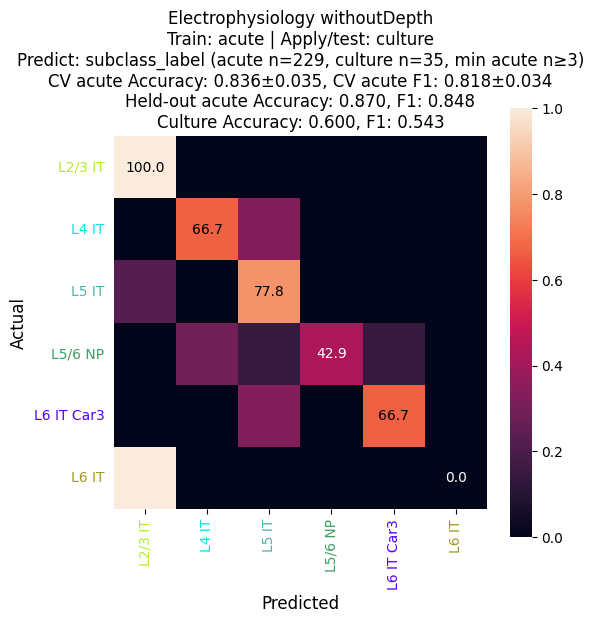

In [12]:
# plot    
for depth_type in depth_types:
    fig_path = os.path.join(
        out_dir,
        'human_excitatory_ephys_classifier_rf_min_{}_cells_{}_acuteTrain_cultureTest{}.pdf'.format(min_num_cells, depth_type, me_tag))

    with PdfPages(fig_path) as pdf:
        with warnings.catch_warnings():
            warnings.simplefilter(action='ignore', category=FutureWarning)

        for label_column in label_columns:

            data = features_imputed
            feature_columns = cols = [c for c in data.columns if not c.endswith('_label_Hierarchical')]
            if depth_type == 'withoutDepth':
                feature_columns.remove('depth_from_pia_norm')

            # filter out data with a nan label_column value
            this_metadata = metadata.dropna(subset=label_column)

            # split acute vs culture
            acute_metadata = this_metadata[this_metadata.paradigm == 'acute']
            culture_metadata = this_metadata[this_metadata.paradigm == 'culture']

            id_column = 'specimen_id'

            acute_data = data.merge(acute_metadata, how='inner', left_index=True, right_index=True)
            culture_data = data.merge(culture_metadata, how='inner', left_index=True, right_index=True)

            # determine labels from ACUTE training pool only
            label_counts = acute_data[label_column].value_counts()
            labels = sorted(label_counts[label_counts >= min_num_cells].index)
            labels = [l for l in label_order[label_column] if l in labels]

            acute_data = acute_data[acute_data[label_column].isin(labels)]
            culture_data = culture_data[culture_data[label_column].isin(labels)]

            num_cells_acute = len(acute_data)
            num_cells_culture = len(culture_data)

            print("\n==============================")
            print(f"{depth_type} | {label_column}")
            print("Acute cells:", num_cells_acute)
            print("Culture cells:", num_cells_culture)
            print("Acute paradigms:", acute_data.paradigm.unique())
            print("Culture paradigms:", culture_data.paradigm.unique())
            print("Labels:", labels)

            if num_cells_acute == 0 or num_cells_culture == 0:
                print("Skipping because acute or culture data is empty.")
                continue

            # 80/20 train/test on acute only
            y = acute_data[label_column]
            X = acute_data[feature_columns]

            X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
                X,
                y,
                acute_data.index,
                stratify=y,
                train_size=0.8,
                random_state=42
            )

            # normalize data: fit on acute train only
            scaler = StandardScaler()
            X_train = scaler.fit_transform(X_train)
            X_test = scaler.transform(X_test)

            # culture apply/test set
            X_culture = culture_data[feature_columns]
            y_culture = culture_data[label_column]
            X_culture = scaler.transform(X_culture)

            print("Train labels:", sorted(y_train.unique()))
            print("Acute test labels:", sorted(y_test.unique()))
            print("Culture labels:", sorted(y_culture.unique()))

            # stratified kfold cross validation
            cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

            # make model
            rf_classifier = RandomForestClassifier(random_state=42, class_weight='balanced')

            param_grid = {
                'n_estimators': [50, 100, 150],
                'max_depth': [5, 10, 15],
                'min_samples_split': [2, 5, 10],
                'min_samples_leaf': [1, 2, 4]
            }

            scoring = {
                'accuracy': 'accuracy',
                'f1_weighted': 'f1_weighted'
            }

            grid_search = GridSearchCV(
                rf_classifier,
                param_grid,
                cv=cv,
                scoring=scoring,
                refit='f1_weighted',
                verbose=1,
                n_jobs=-1,
                return_train_score=False
            )

            grid_search.fit(X_train, y_train)

            best_model = grid_search.best_estimator_
            print("Best Parameters:", grid_search.best_params_)

            cv_results = grid_search.cv_results_
            best_idx = grid_search.best_index_

            cv_acc_mean = cv_results['mean_test_accuracy'][best_idx]
            cv_acc_std = cv_results['std_test_accuracy'][best_idx]

            cv_f1_mean = cv_results['mean_test_f1_weighted'][best_idx]
            cv_f1_std = cv_results['std_test_f1_weighted'][best_idx]

            print(
                f"CV acute train | "
                f"Accuracy: {cv_acc_mean:.3f} ± {cv_acc_std:.3f} | "
                f"F1 weighted: {cv_f1_mean:.3f} ± {cv_f1_std:.3f}"
            )

            # evaluate on held-out acute test
            y_pred = best_model.predict(X_test)

            acute_accuracy = accuracy_score(y_test, y_pred)
            acute_f1_test = f1_score(y_test, y_pred, average='weighted')

            print(f"Held-out acute test | Accuracy: {acute_accuracy:.3f} | F1: {acute_f1_test:.3f}")

            # apply acute-trained classifier to culture
            y_culture_pred = best_model.predict(X_culture)

            culture_accuracy = accuracy_score(y_culture, y_culture_pred)
            culture_f1_test = f1_score(y_culture, y_culture_pred, average='weighted')

            print(f"Culture apply/test | Accuracy: {culture_accuracy:.3f} | F1: {culture_f1_test:.3f}")

            cm = confusion_matrix(y_culture, y_culture_pred, labels=labels)
            true_label_counts = np.sum(cm, axis=1)

            normalized_cm = np.full_like(cm, np.nan, dtype=float)
            valid_rows = true_label_counts > 0
            normalized_cm[valid_rows] = cm[valid_rows] / true_label_counts[valid_rows, np.newaxis]

            row_acc = np.diag(normalized_cm)

            # PLOT culture confusion matrix
            fig, ax = plt.subplots(ncols=1, nrows=1, figsize=fig_sizes[label_column])

            formatted_labels = labels

            sns.heatmap(
                normalized_cm,
                annot=False,
                fmt=".2f",
                cmap="rocket",
                vmin=0,
                vmax=1,
                xticklabels=formatted_labels,
                yticklabels=formatted_labels,
                square=True,
                cbar=True,
                ax=ax
            )

            # Annotate diagonal with % correct per row
            for i in range(len(formatted_labels)):
                val = row_acc[i]
                if not np.isnan(val):
                    ax.text(
                        i + 0.5,
                        i + 0.5,
                        f"{val*100:.1f}",
                        ha="center",
                        va="center",
                        fontsize=10,
                        color="white" if val < 0.5 else "black"
                    )

            plt.xlabel('Predicted', fontsize=12)
            plt.ylabel('Actual', fontsize=12)

            plt.title(
                f'Electrophysiology {depth_type}\n'
                f'Train: acute | Apply/test: culture\n'
                f'Predict: {label_column} '
                f'(acute n={num_cells_acute}, culture n={num_cells_culture}, min acute n≥{min_num_cells})\n'
                f'CV acute Accuracy: {cv_acc_mean:.3f}±{cv_acc_std:.3f}, '
                f'CV acute F1: {cv_f1_mean:.3f}±{cv_f1_std:.3f}\n'
                f'Held-out acute Accuracy: {acute_accuracy:.3f}, F1: {acute_f1_test:.3f}\n'
                f'Culture Accuracy: {culture_accuracy:.3f}, F1: {culture_f1_test:.3f}',
                fontsize=12
            )

            plt.xticks(fontsize=10, rotation=90)
            plt.yticks(fontsize=10, rotation=0)

            # Annotating culture counts on the right side
            for i in range(len(formatted_labels)):
                ax.text(
                    len(formatted_labels) + num_cell_xbuffer[label_column],
                    i + 0.5,
                    int(true_label_counts[i]),
                    ha="center",
                    va="center",
                    fontsize=10,
                    color='grey'
                )

            ax.text(
                len(formatted_labels) + num_cell_xbuffer[label_column],
                n_height[label_column],
                'n',
                ha="center",
                va="center",
                fontsize=10,
                color='grey',
                fontstyle='italic'
            )

            ax.tick_params(axis='y', which='both', left=False, right=False)

            if 'cluster' in label_column:
                for i, l in enumerate(labels):
                    subclass = metadata[metadata[label_column] == l][label_column.replace('cluster', 'subclass')].unique()[0]
                    if i > 0:
                        if last_subclass != subclass:
                            ax.hlines(i, *ax.get_xlim(), color='white', linewidth=1)
                            ax.vlines(i, *ax.get_ylim(), color='white', linewidth=1)
                    last_subclass = subclass

            for label in ax.get_xticklabels():
                text = label.get_text()
                try:
                    label.set_color(color_dict[text])
                except KeyError:
                    continue

            for label in ax.get_yticklabels():
                text = label.get_text()
                try:
                    label.set_color(color_dict[text])
                except KeyError:
                    continue

            plt.tight_layout()
            pdf.savefig(fig, bbox_inches='tight')
            plt.show()

3. Equal acute/culture in train and test. Show test results for acute and culture cells separately. 

Fitting 3 folds for each of 81 candidates, totalling 243 fits
Best Parameters: {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 100}
CV (n=3 folds) | Accuracy: 0.889 ± 0.006 | F1 (weighted): 0.881 ± 0.011


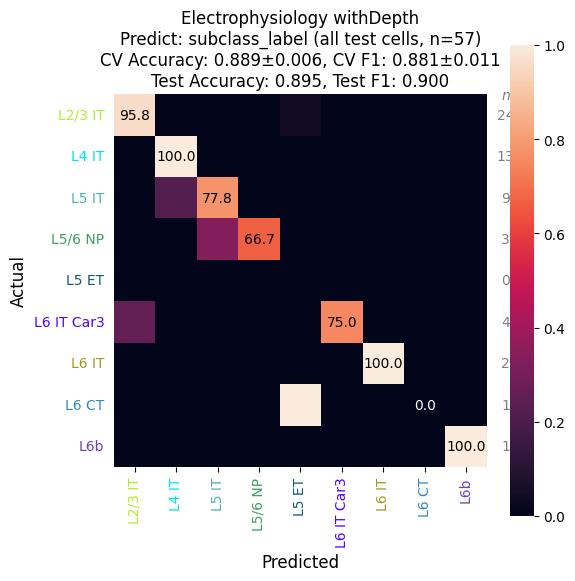

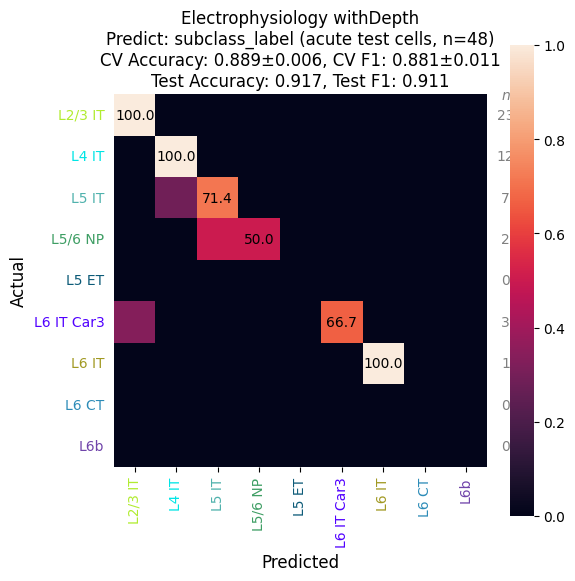

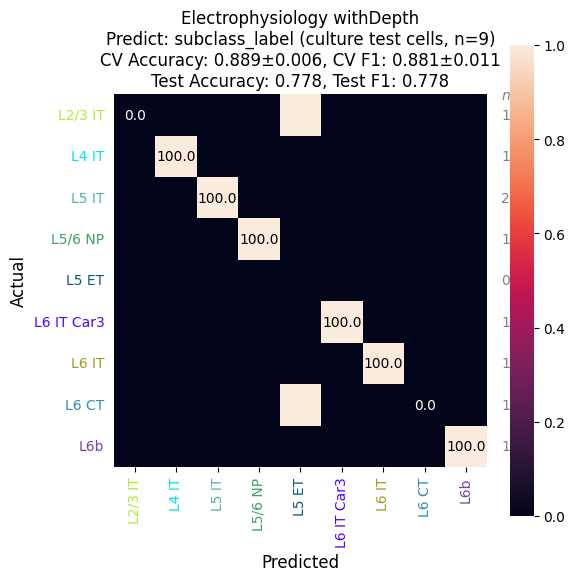

Fitting 3 folds for each of 81 candidates, totalling 243 fits
Best Parameters: {'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 150}
CV (n=3 folds) | Accuracy: 0.818 ± 0.006 | F1 (weighted): 0.797 ± 0.017


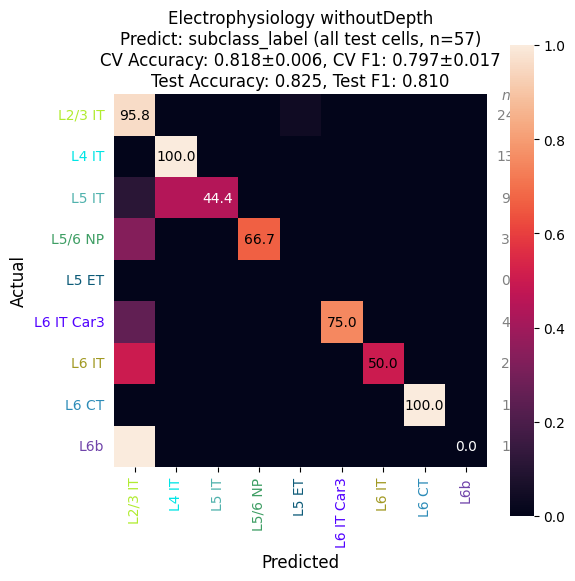

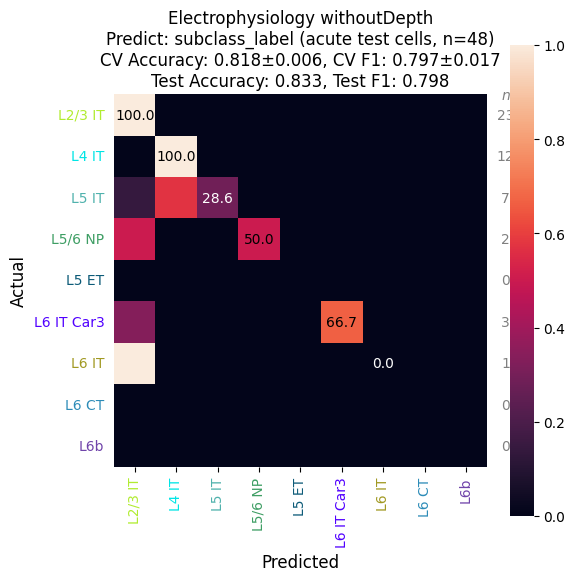

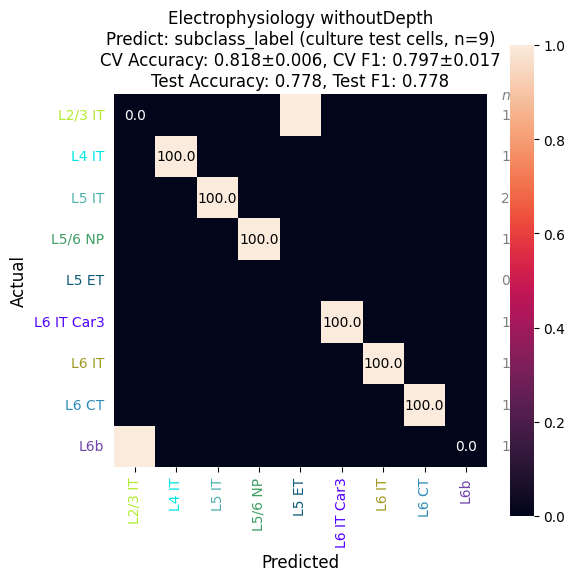

In [13]:
#plot    
for depth_type in depth_types:
    fig_path = os.path.join(out_dir, 'human_excitatory_ephys_classifier_rf_min_{}_cells_{}_balanceParadigm.pdf'.format(min_num_cells, depth_type))
    with PdfPages(fig_path) as pdf:
        with warnings.catch_warnings():
            warnings.simplefilter(action='ignore', category=FutureWarning)


        for label_column in label_columns:

            data = features_imputed
            feature_columns = cols = [c for c in data.columns if not c.endswith('_label_Hierarchical')]
            if depth_type == 'withoutDepth':
                feature_columns.remove('depth_from_pia_norm')

            #filter out data with a nan label_column value
            this_metadata = metadata.dropna(subset=label_column)

            id_column = 'specimen_id'
            data = data.merge(this_metadata, how='inner', left_index=True, right_index=True)
            labels = sorted(data[label_column].unique())

            #filter out data in [ttype] with less than n cells
            label_counts = data[label_column].value_counts()
            labels = sorted(label_counts[label_counts >= min_num_cells].index)
            labels = [l for l in label_order[label_column] if l in labels]
            data = data[data[label_column].isin(labels)]

            num_cells_total = len(data)

            #80/20 : train/test
            # Create a combined stratification label
            stratify_col = data[label_column].astype(str) + "_" + data["paradigm"].astype(str)

            y = data[label_column]
            X = data[feature_columns]
            X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(X, y, data.index, stratify=stratify_col, train_size=0.8, random_state=42)  #80/20 : train/test

            #normalize data
            scaler = StandardScaler() 
            X_train = scaler.fit_transform(X_train) 
            X_test = scaler.transform(X_test)

            #stratified kfold cross validation 
            cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

            #make model 
            rf_classifier = RandomForestClassifier(random_state=42, class_weight='balanced')

            # Hyperparameters to search
            param_grid = {
                'n_estimators': [50, 100, 150],  
                'max_depth': [5, 10, 15],
                'min_samples_split': [2, 5, 10],
                'min_samples_leaf': [1, 2, 4]
            }

            # Perform grid search
            # grid_search = GridSearchCV(rf_classifier, param_grid, cv=cv, verbose=1, n_jobs=-1)

            scoring = {
                'accuracy': 'accuracy',
                'f1_weighted': 'f1_weighted'
            }

            grid_search = GridSearchCV(
                rf_classifier,
                param_grid,
                cv=cv,
                scoring=scoring,
                refit='f1_weighted',   # important
                verbose=1,
                n_jobs=-1,
                return_train_score=False
            )
            grid_search.fit(X_train, y_train)

            # Get the best model
            best_model = grid_search.best_estimator_
            print("Best Parameters:", grid_search.best_params_)

            cv_results = grid_search.cv_results_
            best_idx = grid_search.best_index_

            cv_acc_mean = cv_results['mean_test_accuracy'][best_idx]
            cv_acc_std  = cv_results['std_test_accuracy'][best_idx]

            cv_f1_mean  = cv_results['mean_test_f1_weighted'][best_idx]
            cv_f1_std   = cv_results['std_test_f1_weighted'][best_idx]

            print(
                f"CV (n={cv.get_n_splits()} folds) | "
                f"Accuracy: {cv_acc_mean:.3f} ± {cv_acc_std:.3f} | "
                f"F1 (weighted): {cv_f1_mean:.3f} ± {cv_f1_std:.3f}"
            )

            #test
            y_pred = best_model.predict(X_test)

            # Put test results back into a dataframe so we can subset by paradigm
            test_results = pd.DataFrame({
                "y_true": y_test,
                "y_pred": y_pred,
                "paradigm": data.loc[id_test, "paradigm"]
            }, index=id_test)

            cm_sets = {
                "all test cells": test_results,
                "acute test cells": test_results[test_results["paradigm"] == "acute"],
                "culture test cells": test_results[test_results["paradigm"] == "culture"],
            }

            for cm_title, cm_data in cm_sets.items():

                if len(cm_data) == 0:
                    continue

                cm = confusion_matrix(
                    cm_data["y_true"],
                    cm_data["y_pred"],
                    labels=labels
                )

                true_label_counts = np.sum(cm, axis=1)

                # Avoid divide-by-zero for labels absent in acute/culture subset
                normalized_cm = np.divide(
                    cm,
                    true_label_counts[:, np.newaxis],
                    out=np.zeros_like(cm, dtype=float),
                    where=true_label_counts[:, np.newaxis] != 0
                )

                row_acc = np.diag(normalized_cm)

                accuracy_subset = accuracy_score(cm_data["y_true"], cm_data["y_pred"])
                f1_subset = f1_score(cm_data["y_true"], cm_data["y_pred"], average="weighted")

                fig, ax = plt.subplots(ncols=1, nrows=1, figsize=fig_sizes[label_column])

                formatted_labels = labels

                sns.heatmap(
                    normalized_cm,
                    annot=False,
                    fmt=".2f",
                    cmap="rocket",
                    vmin=0,
                    vmax=1,
                    xticklabels=formatted_labels,
                    yticklabels=formatted_labels,
                    square=True,
                    cbar=True,
                    ax=ax
                )

                for i in range(len(formatted_labels)):
                    val = row_acc[i]
                    if true_label_counts[i] > 0:
                        ax.text(
                            i + 0.5,
                            i + 0.5,
                            f"{val*100:.1f}",
                            ha="center",
                            va="center",
                            fontsize=10,
                            color="white" if val < 0.5 else "black"
                        )

                plt.xlabel("Predicted", fontsize=12)
                plt.ylabel("Actual", fontsize=12)

                plt.title(
                    f"Electrophysiology {depth_type}\n"
                    f"Predict: {label_column} ({cm_title}, n={len(cm_data)})\n"
                    f"CV Accuracy: {cv_acc_mean:.3f}±{cv_acc_std:.3f}, "
                    f"CV F1: {cv_f1_mean:.3f}±{cv_f1_std:.3f}\n"
                    f"Test Accuracy: {accuracy_subset:.3f}, Test F1: {f1_subset:.3f}",
                    fontsize=12
                )

                plt.xticks(fontsize=10, rotation=90)
                plt.yticks(fontsize=10, rotation=0)

                for i in range(len(formatted_labels)):
                    ax.text(
                        len(formatted_labels) + num_cell_xbuffer[label_column],
                        i + 0.5,
                        int(true_label_counts[i]),
                        ha="center",
                        va="center",
                        fontsize=10,
                        color="grey"
                    )

                ax.text(
                    len(formatted_labels) + num_cell_xbuffer[label_column],
                    n_height[label_column],
                    "n",
                    ha="center",
                    va="center",
                    fontsize=10,
                    color="grey",
                    fontstyle="italic"
                )

                ax.tick_params(axis="y", which="both", left=False, right=False)

                if "cluster" in label_column:
                    for i, l in enumerate(labels):
                        subclass = metadata[metadata[label_column] == l][
                            label_column.replace("cluster", "subclass")
                        ].unique()[0]
                        if i > 0:
                            if last_subclass != subclass:
                                ax.hlines(i, *ax.get_xlim(), color="white", linewidth=1)
                                ax.vlines(i, *ax.get_ylim(), color="white", linewidth=1)
                        last_subclass = subclass

                for label in ax.get_xticklabels():
                    text = label.get_text()
                    if text in color_dict:
                        label.set_color(color_dict[text])

                for label in ax.get_yticklabels():
                    text = label.get_text()
                    if text in color_dict:
                        label.set_color(color_dict[text])

                plt.tight_layout()
                pdf.savefig(fig, bbox_inches="tight")
                plt.show()
